# Expirement running multiple ASP programs multiple times to get mean grounding/solving times

### Loading puzzles

In [14]:
import clingo
import time
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

import matplotlib.pyplot as plt
from pathlib import Path

def load_program(puzzle, gen, configuration, base_rules, puzzle_path):
    '''
        Load the necessary lp files to load a complete puzzle:
        - with base file
        - with puzzle world
        - with clues
        and create a clingo control variable
    '''
    ctl = clingo.Control(["0", "--stats=2", "--warn=no-atom-undefined", f"--configuration={configuration}"])
    ctl.load('../solve-experiment.lp')
    ctl.load(f'../{base_rules}')
    if gen:
        ctl.load(f'../autogenerated_puzzles/puzzles/puzzle{puzzle}.lp')
        ctl.load(f'../autogenerated_puzzles/clues/clues{puzzle}.lp')
    else:
        ctl.load(f'{puzzle_path}/puzzle{puzzle}.lp')
        ctl.load(f'../clues/clues{puzzle}.lp')
    ground_start = time.perf_counter()
    ctl.ground([("base", [])])
    ground_time = time.perf_counter() - ground_start
    grounded_at = sum(1 for atom in ctl.symbolic_atoms.by_signature('at', 3)) # grounded placements for people at certain locations
    return ctl, ground_time, grounded_at
 
def solve_puzzle(puzzle, gen=False, count=False, configuration='auto', base_rules='base-rules.lp', debug=False, puzzle_path='../puzzles'):
    '''
        Solve a clingo program by loading an lp file.
        Output atoms
        Output all solutions
    '''
    ctl, ground_time, grounded_at = load_program(puzzle, gen, configuration, base_rules, puzzle_path)
    def on_model(model):
        if debug:
            print(model.symbols(shown=True))
        else:
            pass
    with ctl.solve(on_model=on_model, yield_=True) as handle:
        models = list(handle)
        result = handle.get()
        stats = ctl.statistics
        solve_time = stats['summary']['times']['solve']
        grid_size = ctl.get_const('n').number

        # extract number of clues:
        atoms = ctl.symbolic_atoms
        clue_count = sum(1 for atom in atoms if atom.symbol.name == 'clue')

        #extract the types of clues:
        all_clue_types = ['in_same_room', 'not_in_same_room', 'next_to', 'not_next_to', 'on', 'in', \
                    'in_top_row', 'in_bottom_row', 'in_left_column', 'in_right_column', 'alone', 'not_alone', 'not_in',  'in_corner', 'not_in_corner', 'no_empty_room', \
                    'in_room_with_female', 'not_in_room_with_female', 'in_room_with_male', 'not_in_room_with_male', 'not_on', 'only_one_on',  'n_persons_on', 'in_room_with_multiple_females', 'in_room_with_multiple_males', \
                    'east_of', 'west_of', 'north_of', 'south_of', 'next_to_with_someone_else', 'object_in_col', 'no_object_in_col', 'object_in_row', 'no_object_in_row', \
                    'in_column', 'in_row', 'n_east_of', 'n_west_of', 'n_north_of', 'n_south_of', 'someone_else_in_room_on', 'someone_else_in_room_next_to', 'object_in_same_room']
        clue_type_counts = {}
        for atom in atoms:
            if atom.symbol.name == 'clue':
                args = [str(arg) for arg in atom.symbol.arguments]
                for arg in args:
                    if arg in all_clue_types:
                        clue_type_counts[arg] = clue_type_counts.setdefault(arg, 0) + 1

    if count:
        print(f'Number of models: {len(models)}')
        
    if debug:
        print(result)
        print("Satisfiable:", result.satisfiable)
        print("Unsatisfiable:", result.unsatisfiable)
        print("Unknown:", result.unknown)
    return result, ground_time, solve_time, grid_size, clue_count, clue_type_counts, models, grounded_at

#### Store results

In [15]:
def store_result(results, epoch, puzzle, type, ground_time, solve_time, total_time, grid_size, clue_count, clue_type_counts, solve_state, num_solutions, choice_type, grounded_at, constraint_type):
    results.append({
        'epoch': epoch, # epoch
        'puzzle': puzzle, # puzzle number
        'type': type, # automated puzzles with 'type': 'A' manual with 'M', comes from file names.
        'ground_time': ground_time, # time spent on grounding all possibilities
        'solve_time': solve_time, # time spent on solving all grounded rules
        'total_time': total_time, # total time
        'grid_size': grid_size, # grid size of puzzle X*X
        'clue_count': clue_count, # number of clues
        'clue_type_counts': clue_type_counts, # dictionary with types of clues
        'solve_state': solve_state, # is puzzle satisfiable
        'num_solutions': num_solutions, # number of solutions, should always be 1
        'choice_type': choice_type, # normal
        'grounded_at': grounded_at, # add number of grounded at/3 predicates
        'constraint_type': constraint_type # type of constraint for unique row and col
    })

### Small experiment with dynamic choice rules vs normal choice rules

In [4]:
epochs=5
puzzles = list(Path('../puzzles_dynamic').glob("puzzle*.lp"))
results_choice = []

for i in range(epochs):
    print(f'start epoch {i+1}/{epochs}')

    for p in puzzles:
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        print(f'Puzzle #{puzzle_id}, {puzzle_type}, {puzzle_type == 'A'}')
        result, ground_time, solve_time, grid_size, clue_count, clue_type_counts, models, grounded_at = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules.lp')
        result_dyn, ground_time_dyn, solve_time_dyn, grid_size_dyn, clue_count_dyn, clue_type_counts_dyn, models_dyn, grounded_at_dyn = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules-dyn.lp', puzzle_path='../puzzles_dynamic')

        store_result(results_choice, i, puzzle_num, puzzle_type, ground_time, solve_time, ground_time + solve_time, grid_size + 1, clue_count, clue_type_counts, result.satisfiable, len(models), 'Normal', grounded_at, 'Normal')
        store_result(results_choice, i, puzzle_num, puzzle_type, ground_time_dyn, solve_time_dyn, ground_time_dyn + solve_time_dyn, grid_size_dyn + 1, clue_count_dyn, clue_type_counts_dyn, result_dyn.satisfiable, len(models_dyn), 'Dynamic', grounded_at_dyn, 'Normal')

    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

start epoch 1/5
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
end epoch 1/5

----------------------------------

start epoch 2/5
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
end epoch 2/5

----------------------------------

start epoch 3/5
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
end epoch 3/5

----------------------------------

start epoch 4/5


In [34]:
# put results in pandas frame
df_choice = pd.DataFrame(results_choice)
df_choice.head()

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,clue_type_counts,solve_state,num_solutions,choice_type,grounded_at,constraint_type
0,0,30,M,0.393654,0.065509,0.459163,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,Normal,549,Normal
1,0,30,M,0.262843,0.071803,0.334646,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,Dynamic,549,Normal
2,0,55,M,0.292105,0.160066,0.452171,9,14,"{'on': 2, 'in_same_room': 1, 'in_room_with_mul...",True,1,Normal,540,Normal
3,0,55,M,0.276998,0.330582,0.607581,9,14,"{'on': 2, 'in_same_room': 1, 'in_room_with_mul...",True,1,Dynamic,540,Normal
4,0,45,M,0.315320,0.127061,0.442381,9,12,"{'in': 1, 'east_of': 1, 'south_of': 1, 'next_t...",True,1,Normal,531,Normal


In [35]:
# check for failed solutions or multiple solutions
failed = df_choice[df_choice['solve_state'] == False]
len(failed)

0

In [36]:
# check for failed solutions or multiple (or no) solutions
wrong_sol = df_choice[df_choice['num_solutions'] != 1]
len(wrong_sol)

0

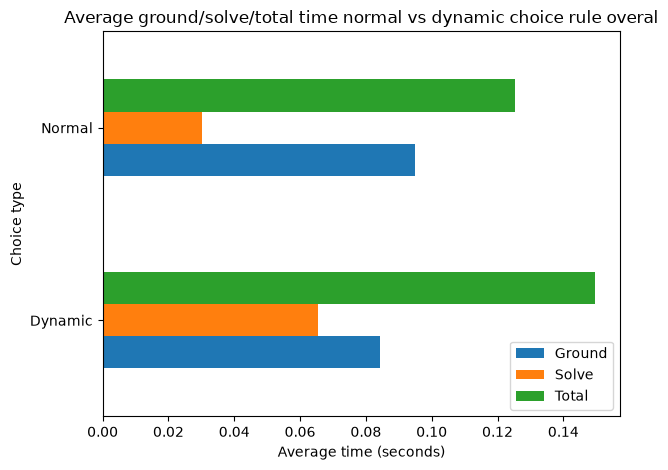

In [330]:
# compare number of ground predicates for at/3 in resulting grounded program
df_choice.groupby('choice_type')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.title('Average ground/solve/total time normal vs dynamic choice rule overal')
plt.ylabel('Choice type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

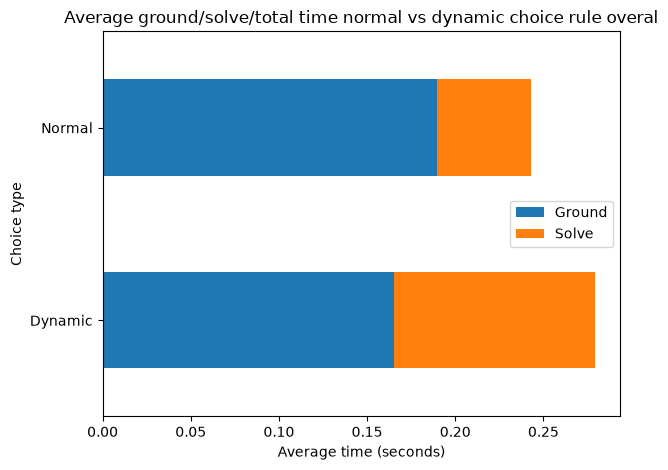

In [37]:
# compare number of ground predicates for at/3 in resulting grounded program
df_choice.groupby('choice_type')[['ground_time','solve_time']].mean().plot(kind='barh', stacked=True)

plt.title('Average ground/solve/total time normal vs dynamic choice rule overal')
plt.ylabel('Choice type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve'])
plt.tight_layout()
plt.show()

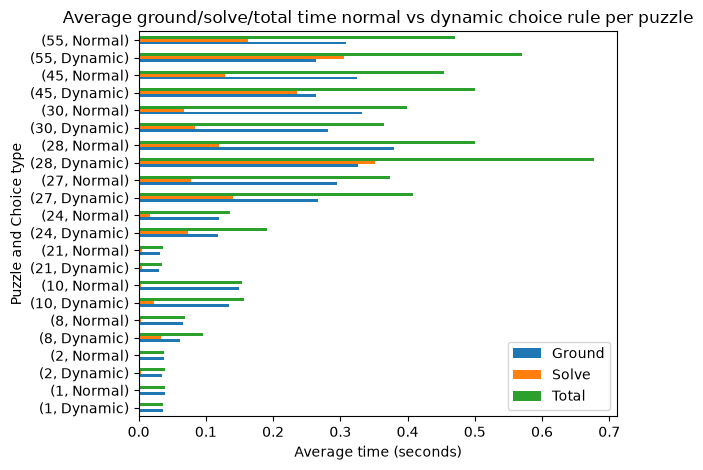

In [49]:
# compare number of ground predicates for at/3 in resulting grounded program
df_choice.groupby(['puzzle', 'choice_type'])[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.title('Average ground/solve/total time normal vs dynamic choice rule per puzzle')
plt.ylabel('Puzzle and Choice type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

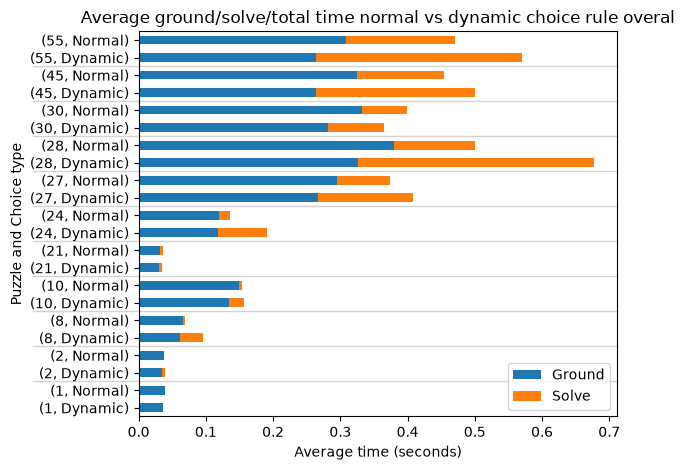

In [44]:
# compare number of ground predicates for at/3 in resulting grounded program
df_choice.groupby(['puzzle', 'choice_type'])[['ground_time','solve_time']].mean().plot(kind='barh', stacked=True)

plt.title('Average ground/solve/total time normal vs dynamic choice rule overal')
plt.ylabel('Puzzle and Choice type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve'])
plt.tight_layout()

# Get the current axes
ax = plt.gca()

# Iterate through the y-ticks and add a light gray line every 2 bars
for i in range(1, len(ax.get_yticks()) - 1, 2):
    plt.axhline(y=i + 0.5, color='lightgray', linewidth=1, zorder=0, xmin=-0.22, clip_on=False)

plt.show()

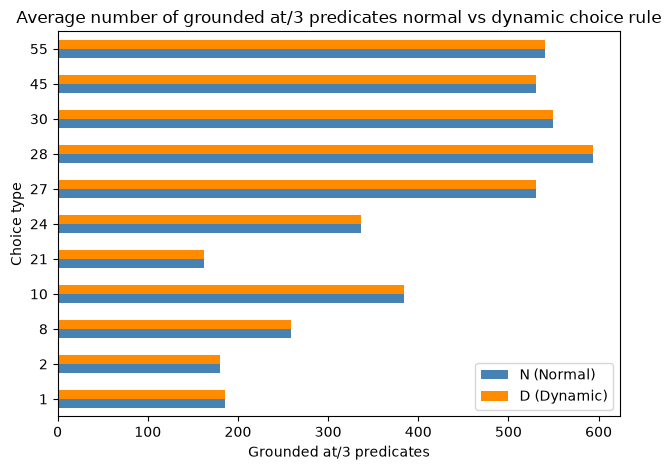

In [50]:
# compare ground_time/solve_time/total_time for both approaches
df_choice.groupby(['puzzle','choice_type'])[['grounded_at']].mean().unstack('choice_type').plot(
    kind='barh', color=['steelblue', 'darkorange']
)

plt.title('Average number of grounded at/3 predicates normal vs dynamic choice rule')
plt.ylabel('Choice type')
plt.xlabel('Grounded at/3 predicates')
plt.legend(['N (Normal)', 'D (Dynamic)'])
plt.tight_layout()
plt.show()

#### Small experiment between normal constraints and aggregate constraints
```ASP
:- person(P1), person(P2), at(P1,R1,C1), at(P2,R2,C2), R1=R2, P1!=P2.
:- person(P1), person(P2), at(P1,R1,C1), at(P2,R2,C2), C1=C2, P1!=P2.
```

VS

```ASP
:- at(_,_,C), #count{P : at(P,R,C)} != 1.
:- at(_,R,_), #count{P : at(P,R,C)} != 1.
```

In [47]:
epochs=5
puzzles = list(Path('../puzzles').glob("puzzle*.lp"))
results_agg = []

for i in range(epochs):
    print(f'start epoch {i+1}/{epochs}')

    for p in puzzles:
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        print(f'Puzzle #{puzzle_id}, {puzzle_type}, {puzzle_type == 'A'}')
        result, ground_time, solve_time, grid_size, clue_count, clue_type_counts, models, grounded_at = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules.lp')
        result_dyn, ground_time_dyn, solve_time_dyn, grid_size_dyn, clue_count_dyn, clue_type_counts_dyn, models_dyn, grounded_at_dyn = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules-agg.lp')

        store_result(results_agg, i, puzzle_num, puzzle_type, ground_time, solve_time, ground_time + solve_time, grid_size + 1, clue_count, clue_type_counts, result.satisfiable, len(models), 'Normal', grounded_at, 'Normal')
        store_result(results_agg, i, puzzle_num, puzzle_type, ground_time_dyn, solve_time_dyn, ground_time_dyn + solve_time_dyn, grid_size_dyn + 1, clue_count_dyn, clue_type_counts_dyn, result_dyn.satisfiable, len(models_dyn), 'Normal', grounded_at_dyn, 'Aggregate')

    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

start epoch 1/5
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
end epoch 1/5

----------------------------------

start epoch 2/5
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
end epoch 2/5

----------------------------------

start epoch 3/5
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
end epoch 3/5

----------------------------------

start epoch 4/5


In [51]:
# put results in pandas dataframe
# put results in pandas frame
df_agg = pd.DataFrame(results_agg)
df_agg.head()


,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,clue_type_counts,solve_state,num_solutions,choice_type,grounded_at,constraint_type
0,0,30,M,0.373390,0.074951,0.448341,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,Normal,549,Normal
1,0,30,M,0.307251,0.029701,0.336952,9,10,"{'next_to': 3, 'in': 1, 'not_in': 1, 'only_one...",True,1,Normal,549,Aggregate
2,0,55,M,0.351510,0.175531,0.527041,9,14,"{'on': 2, 'in_same_room': 1, 'in_room_with_mul...",True,1,Normal,540,Normal
3,0,55,M,0.300309,0.263131,0.563440,9,14,"{'on': 2, 'in_same_room': 1, 'in_room_with_mul...",True,1,Normal,540,Aggregate
4,0,45,M,0.340245,0.125282,0.465527,9,12,"{'in': 1, 'east_of': 1, 'south_of': 1, 'next_t...",True,1,Normal,531,Normal


In [52]:
# check for failed solutions or multiple solutions
failed_agg = df_agg[df_agg['solve_state'] == False]
len(failed_agg)

0

In [53]:
# check for failed solutions or multiple solutions
wrong_sol_agg = df_agg[df_agg['num_solutions'] != 1]
len(wrong_sol_agg)

0

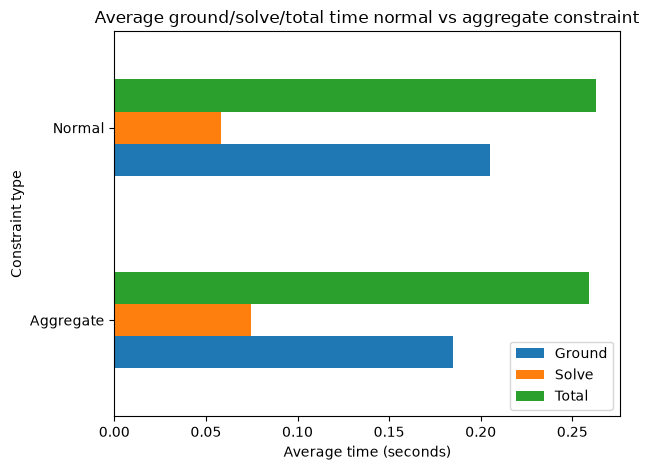

In [57]:
# compare number of ground predicates for at/3 in resulting grounded program
df_agg.groupby('constraint_type')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.title('Average ground/solve/total time normal vs aggregate constraint')
plt.ylabel('Constraint type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

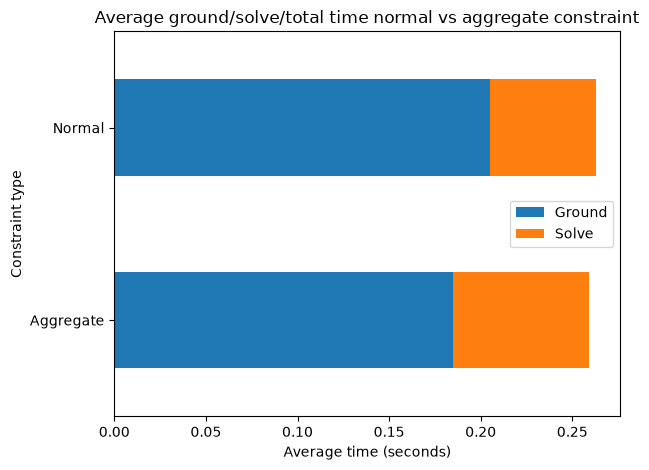

In [55]:
# compare number of ground predicates for at/3 in resulting grounded program
df_agg.groupby('constraint_type')[['ground_time','solve_time']].mean().plot(kind='barh', stacked=True)

plt.title('Average ground/solve/total time normal vs aggregate constraint')
plt.ylabel('Constraint type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve'])
plt.tight_layout()
plt.show()

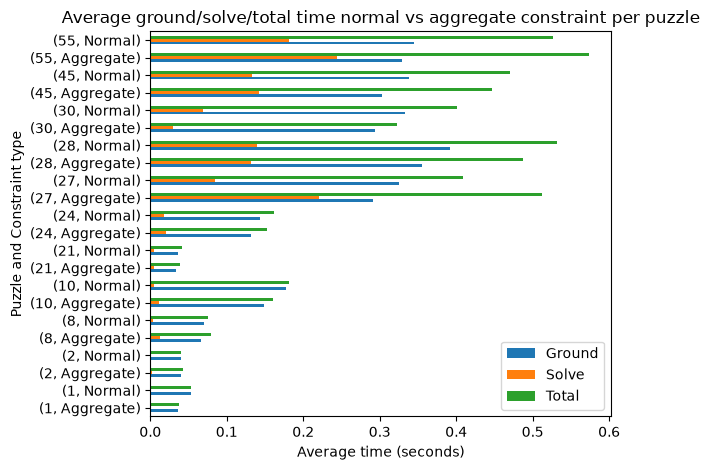

In [58]:
# compare number of ground predicates for at/3 in resulting grounded program
df_agg.groupby(['puzzle', 'constraint_type'])[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.title('Average ground/solve/total time normal vs aggregate constraint per puzzle')
plt.ylabel('Puzzle and Constraint type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()

plt.show()

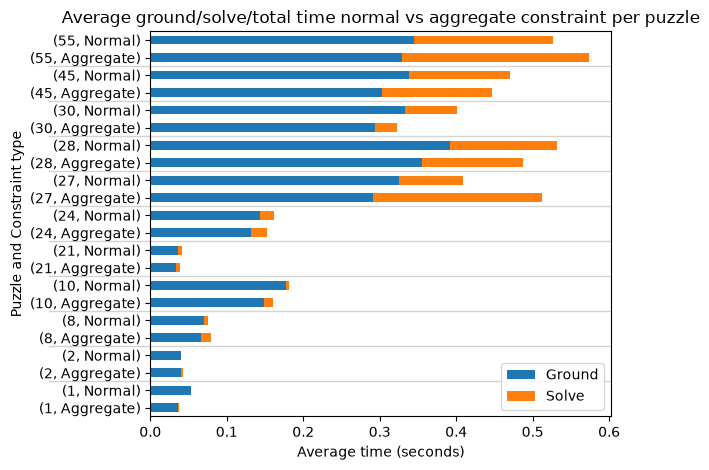

In [56]:
# compare number of ground predicates for at/3 in resulting grounded program
df_agg.groupby(['puzzle', 'constraint_type'])[['ground_time','solve_time']].mean().plot(kind='barh', stacked=True)

plt.title('Average ground/solve/total time normal vs aggregate constraint per puzzle')
plt.ylabel('Puzzle and Constraint type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve'])
plt.tight_layout()

# Get the current axes
ax = plt.gca()

# Iterate through the y-ticks and add a light gray line every 2 bars
for i in range(1, len(ax.get_yticks()) - 1, 2):
    plt.axhline(y=i + 0.5, color='lightgray', linewidth=1, zorder=0, xmin=-0.22, clip_on=False)

plt.show()

For most of the puzzles the aggregate constraints reduce the grounding time, but solving time can drastically increase as well. Maybe compare this on the complete set. There are just 2 puzzles where aggregate constraints take longer in total.
Overall it also shows grounding is faster, but solving is slower, in total there doesn't seem to be a difference in this limited set.

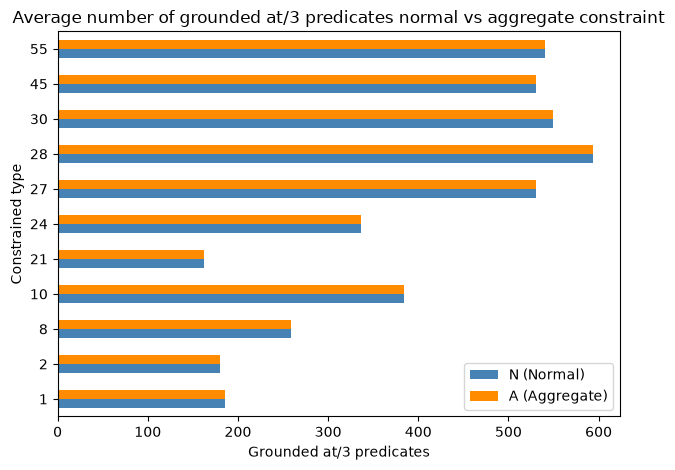

In [342]:
# compare ground_time/solve_time/total_time for both approaches
df_agg.groupby(['puzzle','constraint_type'])[['grounded_at']].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange']
)

plt.title('Average number of grounded at/3 predicates normal vs aggregate constraint')
plt.ylabel('Constrained type')
plt.xlabel('Grounded at/3 predicates')
plt.legend(['N (Normal)', 'A (Aggregate)'])
plt.tight_layout()
plt.show()

## Run main experiment
- epoch is one run of all available puzzles
- type 'M' puzzles are manually taken from Murdoku book 1
- type 'A' puzzles are automatically generated with our Murdoku-generator
- statistics like grounding time, solving time, total time, grid size and number of clues are stored per puzzle per epoch, these can later be used for analysis
- Python vs ASP vs ASP with aggregate constraints


In [61]:
import sys
import importlib

# Reload the module after it has been updated
project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root))

import solver.pythonsolver as pythonsolver


importlib.reload(pythonsolver)


<module 'solver.pythonsolver' from '/Users/tony/Documents/Open Universiteit/Model-based AI/Assignment/murdoku-solve/solver/pythonsolver.py'>

In [64]:
# number of runs for experiment
epochs = 1
debug = True

puzzles = list(Path('../puzzles').glob("puzzle*.lp"))
puzzles_gen = list(Path('../autogenerated_puzzles/puzzles').glob('puzzle*.lp'))
puzzles.extend(puzzles_gen)
results = []
for i in range(epochs):
    if debug:
        print(f'start epoch {i+1}/{epochs}')

    for ip, p in enumerate(puzzles):
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        grid_size_from_file_name = int(puzzle_id.split('-')[0][1:])
        if debug:
            print(f'Puzzle #{puzzle_id}, {puzzle_type}, {puzzle_type == 'A'}')

        # run both ASP implementations
        result, ground_time, solve_time, grid_size, clue_count, clue_type_counts, models, grounded_at = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules.lp')
        result_agg, ground_time_agg, solve_time_agg, grid_size_agg, clue_count_agg, clue_type_counts_agg, models_agg, grounded_at_agg = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules-agg.lp')

        # run python solver:                
        puzzle_base_path = '..' if puzzle_type == 'M' else '../autogenerated_puzzles'
        pfile = f'{puzzle_base_path}/puzzles/puzzle{puzzle_type}{grid_size_from_file_name}-{puzzle_num}.lp'
        cfile = f'{puzzle_base_path}/clues/clues{puzzle_type}{grid_size_from_file_name}-{puzzle_num}.lp'
        n_sol_python, interpret_time_python, solve_time_python, solutions_python, n_clues_python, clue_type_counts_python = pythonsolver.find_solutions(pfile, cfile)

        # store results for 3 methods:
        store_result(results, i, puzzle_num, puzzle_type, ground_time, solve_time, ground_time + solve_time, grid_size + 1, clue_count, clue_type_counts, result.satisfiable, len(models), 'ASP', grounded_at, 'Normal')
        store_result(results, i, puzzle_num, puzzle_type, ground_time_agg, solve_time_agg, ground_time_agg + solve_time_agg, grid_size + 1, clue_count, clue_type_counts, result_agg.satisfiable, len(models_agg), 'ASP', grounded_at_agg, 'Aggregate')
        store_result(results, i, puzzle_num, puzzle_type, interpret_time_python, solve_time_python, interpret_time_python + solve_time_python, grid_size_from_file_name, n_clues_python, clue_type_counts_python, n_sol_python>0, n_sol_python, 'Python', None, 'Python')

        if ip > 0 and ip % 50 == 0:
            print(f'epoch {i+1}/{epochs} at {ip}/{len(puzzles)} puzzles')

    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

start epoch 1/1
Puzzle #M9-30, M, False
Puzzle #M9-55, M, False
Puzzle #M9-45, M, False
Puzzle #M6-1, M, False
Puzzle #M8-10, M, False
Puzzle #M8-24, M, False
Puzzle #M6-21, M, False
Puzzle #M6-2, M, False
Puzzle #M9-28, M, False
Puzzle #M7-8, M, False
Puzzle #M9-27, M, False
Puzzle #A6-69, A, True
Puzzle #A13-58, A, True
Puzzle #A7-94, A, True
Puzzle #A5-80, A, True
Puzzle #A9-97, A, True
Puzzle #A6-38, A, True
Puzzle #A9-64, A, True
Puzzle #A10-42, A, True
Puzzle #A8-99, A, True
Puzzle #A5-73, A, True
Puzzle #A7-36, A, True
Puzzle #A10-13, A, True
Puzzle #A9-35, A, True
Puzzle #A5-22, A, True
Puzzle #A7-67, A, True
Puzzle #A12-56, A, True
Puzzle #A10-9, A, True
Puzzle #A11-78, A, True
Puzzle #A4-49, A, True
Puzzle #A10-85, A, True
Puzzle #A12-91, A, True
Puzzle #A11-29, A, True
Puzzle #A4-18, A, True
Puzzle #A7-53, A, True
Puzzle #A12-62, A, True
Puzzle #A6-8, A, True
Puzzle #A10-27, A, True
Puzzle #A5-16, A, True
Puzzle #A12-33, A, True
Puzzle #A10-76, A, True
Puzzle #A9-50, A, True

KeyboardInterrupt: 

### Analyze
- convert results to Pandas DataFrame for easy evaluation

#### Error checks
- check for unsatisfiable puzzles
- check for puzzles with multiple solutions

#### Compare results
- Compare results between approaches
- Compare performance between puzzles (commented out)
- Compare performance between grid sizes
- Compare performance between number of clues
- Compare performance between generated and manual puzzles
- Compare performance between combination of grid size and number of clues
- Compare performance between combination of grid size and generated/manual

In [472]:
len(results)

3177

In [473]:
# convert to pandas dataframe for further inspection
df = pd.DataFrame(results)
df.head()


,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions,choice_type,grounded_at,constraint_type
0,0,30,M,0.180567,0.041509,0.222076,9,10,True,1,ASP,549.0,Normal
1,0,30,M,0.137872,0.017806,0.155678,9,10,True,1,ASP,549.0,Aggregate
2,0,30,M,0.000263,0.001735,0.001998,9,10,True,1,Python,NaN,Python
3,0,55,M,0.164362,0.094367,0.258729,9,14,True,1,ASP,540.0,Normal
4,0,55,M,0.144290,0.138031,0.282321,9,14,True,1,ASP,540.0,Aggregate


### Store results

In [493]:
df.to_csv('main-results.csv', index=False)

In [ ]:
# reload results
df = pd.read_csv('main-results.csv')

### Compare Python vs ASP vs ASP with aggregate constraint

In [474]:
print(len(df[df['constraint_type'] == 'Normal'][['puzzle','type','grid_size']]))
print(len(df[df['constraint_type'] == 'Python'][['puzzle','type','grid_size']]))
print(len(df[df['constraint_type'] == 'Aggregate'][['puzzle','type','grid_size']]))

1059
1059
1059


In [476]:
# check for unresolved puzzles
(~df['solve_state']).sum()

np.int64(0)

In [477]:
# check for puzzles with multiple solutions
multi_solutions = df[(df['num_solutions'] > 1) & (df['epoch'] == 0)]
multi_solutions

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions,choice_type,grounded_at,constraint_type


In [478]:
# get average times per method
df.groupby('constraint_type')[['ground_time','solve_time','total_time']].mean()

,ground_time,solve_time,total_time
constraint_type,,,
Aggregate,0.583947,1.937147,2.521094
Normal,0.670477,1.926527,2.597003
Python,0.000310,0.533413,0.533722


In [479]:
# Check whether each puzzle is solved once per epoch per method
df.groupby(['epoch','puzzle', 'type', 'grid_size', 'constraint_type']).size().sort_values(ascending=False)

epoch  puzzle  type  grid_size  constraint_type
0      1       A     4          Aggregate          1
       65      A     8          Normal             1
                     9          Aggregate          1
                                Normal             1
                                Python             1
                                                  ..
       32      A     8          Aggregate          1
                                Normal             1
                                Python             1
                     9          Aggregate          1
       100     A     13         Python             1
Length: 3177, dtype: int64

In [480]:
# get mean scores per puzzle per method and find longest total time
df.groupby(['puzzle', 'type', 'grid_size', 'constraint_type'])[
    ['ground_time', 'solve_time', 'total_time']
].mean().sort_values('total_time', ascending=False).head(30)

,,,,ground_time,solve_time,total_time
puzzle,type,grid_size,constraint_type,,,
28,M,9,Python,0.000247,90.099456,90.099703
34,A,14,Normal,3.518116,50.039314,53.557430
41,A,14,Aggregate,3.026592,42.067854,45.094446
44,A,13,Aggregate,2.036216,41.174583,43.210799
18,A,14,Normal,3.736032,36.200524,39.936556
52,A,13,Normal,2.293384,36.782576,39.075960
12,A,14,Aggregate,3.222211,33.131216,36.353427
10,A,14,Normal,4.044384,31.877809,35.922193
12,A,14,Normal,3.680863,32.201116,35.881980


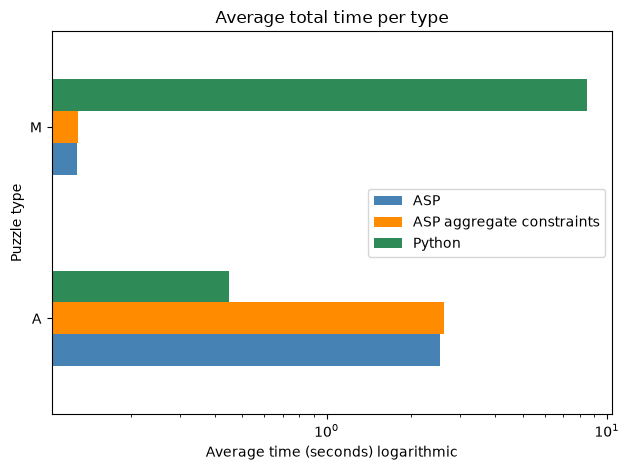

In [481]:
# average ground/solve/total times per method
ax = df.groupby(['type', 'constraint_type'])['total_time'].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)

ax.set_xscale('log')
plt.ylabel('Puzzle type')
plt.xlabel('Average time (seconds) logarithmic')
plt.title('Average total time per type')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'])
plt.tight_layout()
plt.show()

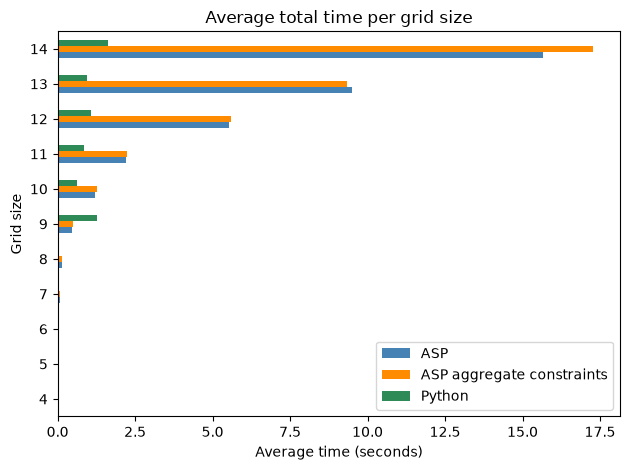

In [482]:
# Compare average total time spend per grid size between methods
ax = df.groupby(['grid_size', 'constraint_type'])['total_time'].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)

plt.ylabel('Grid size')
plt.xlabel('Average time (seconds)')
plt.title('Average total time per grid size')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'], loc='lower right')
plt.tight_layout()
plt.show()

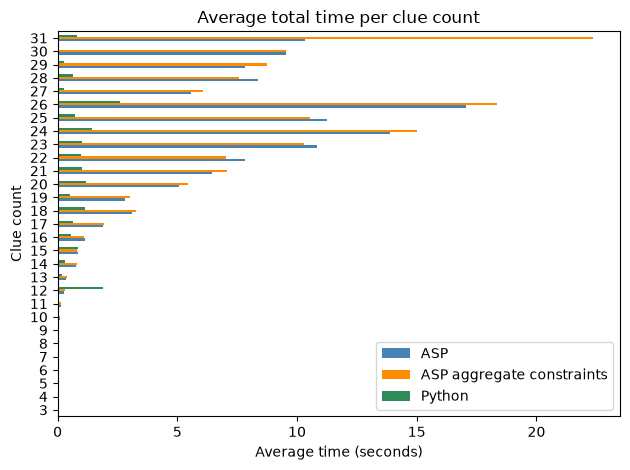

In [483]:
# Compare average total time spend per clue size between methods
ax = df.groupby(['clue_count', 'constraint_type'])['total_time'].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)

plt.ylabel('Clue count')
plt.xlabel('Average time (seconds)')
plt.title('Average total time per clue count')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'], loc='lower right')
plt.tight_layout()
plt.show()

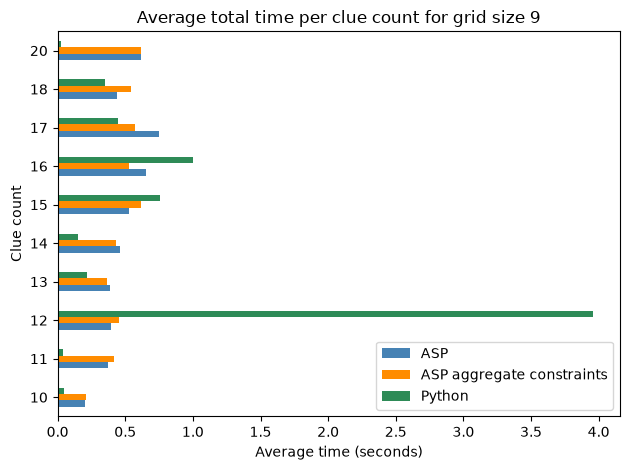

In [484]:
# One interesting combination seems to be clue count = 12 and grid size = 9
# Compare average total time spend per clue size for grid size = 9 between methods
df_grid_size_9 = df[df['grid_size'] == 9]

ax = df_grid_size_9.groupby(['clue_count', 'constraint_type'])['total_time'].mean().unstack('constraint_type').plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)

plt.ylabel('Clue count')
plt.xlabel('Average time (seconds)')
plt.title('Average total time per clue count for grid size 9')
plt.legend(['ASP', 'ASP aggregate constraints', 'Python'], loc='lower right')
plt.tight_layout()
plt.show()

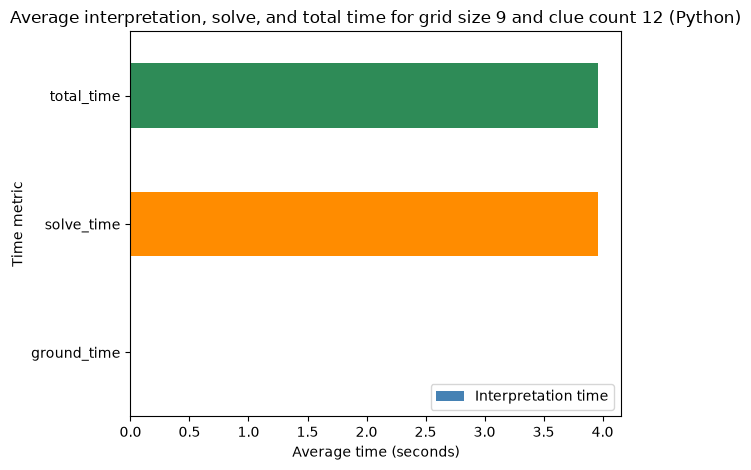

In [485]:
# One interesting combination seems to be clue count = 12 and grid size = 9
# Compare average ground/solve/total time spend
df_grid_size_9_clue_size_12_python = df[(df['grid_size'] == 9) & (df['clue_count'] == 12) & (df['constraint_type'] == 'Python')]

ax = df_grid_size_9_clue_size_12_python[['ground_time','solve_time','total_time']].mean().plot(
    kind='barh', color=['steelblue', 'darkorange','seagreen']
)
plt.ylabel('Time metric')
plt.xlabel('Average time (seconds)')
plt.title('Average interpretation, solve, and total time for grid size 9 and clue count 12 (Python)')
plt.legend(['Interpretation time', 'Solve time', 'Total time'], loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
# Must be solving time then, it is because of Manual input puzzle 28 which has 90 seconds of solving time. Inspect?
df_grid_size_9_clue_size_12_python.head(100) 

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions,choice_type,grounded_at,constraint_type
8,0,45,M,0.000245,2.911779,2.912024,9,12,True,1,Python,NaN,Python
26,0,28,M,0.000247,90.099456,90.099703,9,12,True,1,Python,NaN,Python
71,0,35,A,0.000248,0.032973,0.033221,9,12,True,1,Python,NaN,Python
125,0,50,A,0.000241,0.061424,0.061665,9,12,True,1,Python,NaN,Python
146,0,40,A,0.000254,0.007858,0.008112,9,12,True,1,Python,NaN,Python
167,0,11,A,0.000241,0.000690,0.000931,9,12,True,1,Python,NaN,Python
266,0,54,A,0.000246,0.002115,0.002361,9,12,True,1,Python,NaN,Python
401,0,15,A,0.000352,0.079403,0.079755,9,12,True,1,Python,NaN,Python
524,0,61,A,0.000249,0.003404,0.003653,9,12,True,1,Python,NaN,Python
809,0,24,A,0.000234,0.000321,0.000555,9,12,True,1,Python,NaN,Python


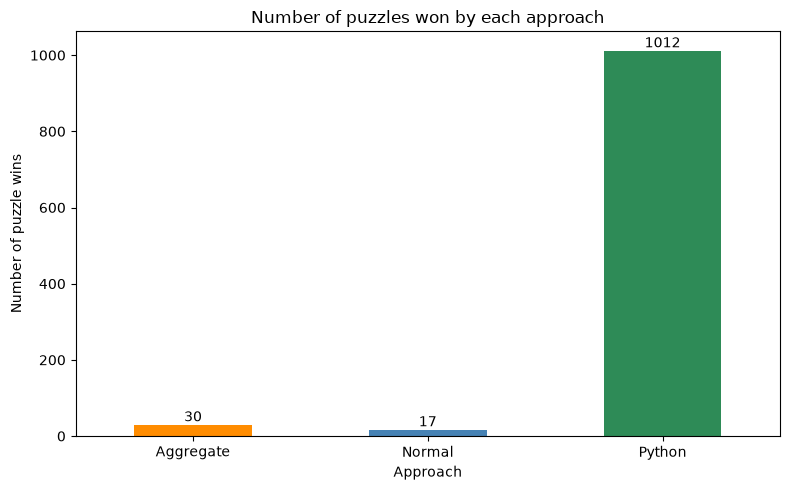

In [492]:
# Compare winner based on total time spent per puzzle averages
avg_total_times = df.groupby(['puzzle','type','grid_size','constraint_type'])['total_time'].mean().unstack('constraint_type')
winners = avg_total_times.idxmin(axis=1)
win_counts = winners.value_counts().reindex(avg_total_times.columns, fill_value=0)

colors = {
    'Normal': 'steelblue',
    'Aggregate': 'darkorange',
    'Python': 'seagreen'
}

ax = win_counts.plot(
    kind='bar',
    color=[colors[t] for t in win_counts.index],
    figsize=(8, 5)
)

ax.set_xlabel('Approach')
ax.set_ylabel('Number of puzzle wins')
ax.set_title('Number of puzzles won by each approach')
ax.bar_label(ax.containers[0], fmt='%d')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [240]:
df.groupby('puzzle')[['ground_time', 'solve_time', 'total_time']].mean()

,ground_time,solve_time,total_time
puzzle,,,
1,0.150346,0.096850,0.247196
2,0.158316,0.743289,0.901605
3,0.175248,0.078590,0.253837
4,0.104929,0.051497,0.156427
5,0.111627,0.086437,0.198064
...,...,...,...
96,0.111725,0.056551,0.168275
97,0.112015,0.084707,0.196722
98,0.108109,0.042743,0.150852


In [241]:
df.groupby('grid_size')[['ground_time', 'solve_time', 'total_time']].mean()

,ground_time,solve_time,total_time
grid_size,,,
4,0.003783,0.000329,0.004112
5,0.009235,0.001381,0.010616
6,0.021491,0.003923,0.025414
7,0.046995,0.014286,0.061282
8,0.096156,0.051067,0.147223
9,0.191893,0.135699,0.327592
10,0.361391,0.591928,0.953319
11,0.645106,2.302929,2.948034


In [242]:
# df.groupby('puzzle')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

# plt.ylabel('Puzzle')
# plt.xlabel('Average time (seconds)')
# plt.title('Average ground/solve/total time per puzzle')
# plt.legend(['Ground', 'Solve', 'Total'])
# plt.tight_layout()
# plt.show()

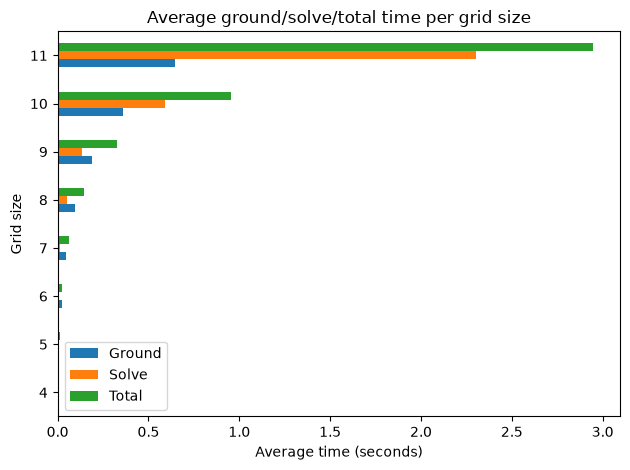

In [243]:
df.groupby('grid_size')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Grid size')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per grid size')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

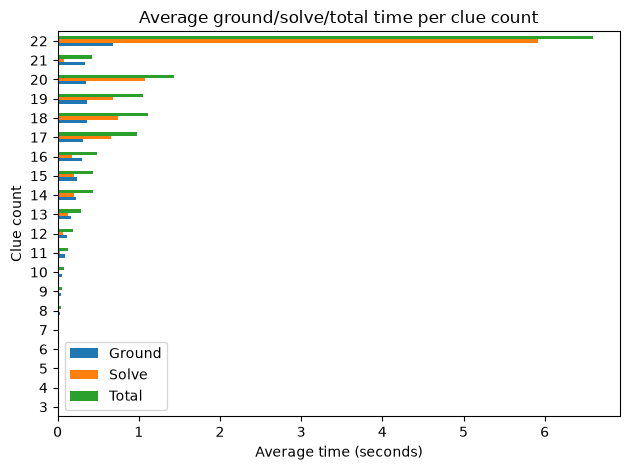

In [244]:
df.groupby('clue_count')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Clue count')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per clue count')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

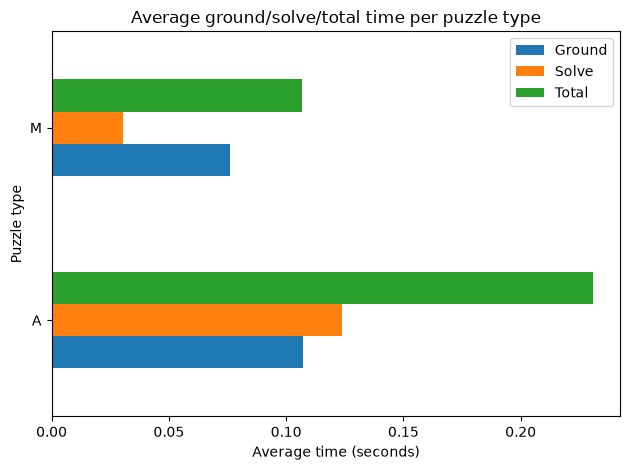

In [245]:
df.groupby('type')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Puzzle type')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per puzzle type')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

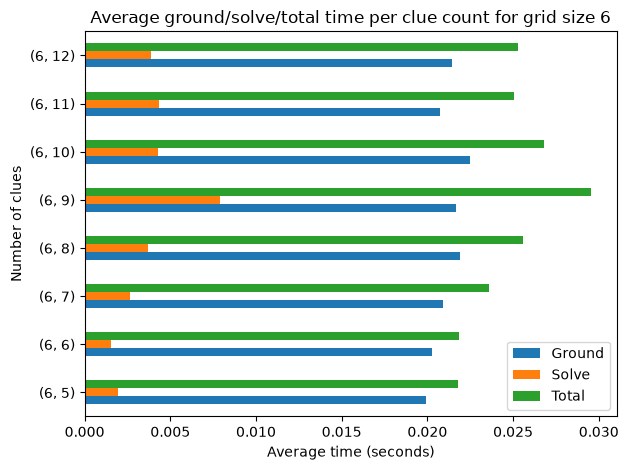

In [246]:
df_6 = df[df['grid_size'] == 6]
df_6.groupby(['grid_size','clue_count'])[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Number of clues')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per clue count for grid size 6')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

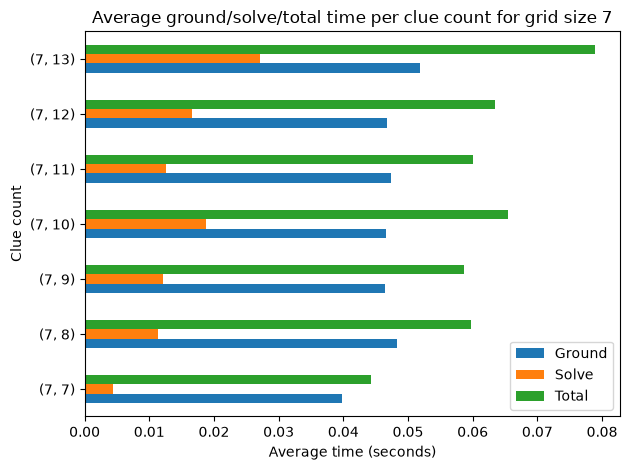

In [247]:
df_7 = df[df['grid_size'] == 7]
df_7.groupby(['grid_size','clue_count'])[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Clue count')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per clue count for grid size 7')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

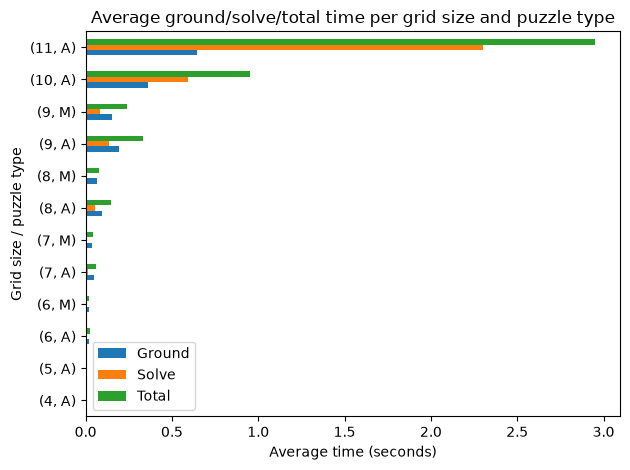

In [248]:
df.groupby(['grid_size', 'type'])[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Grid size / puzzle type')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per grid size and puzzle type')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

In [33]:
#linear regression on the most important variables
results = pd.DataFrame(results_choice)

dependent_variables = ['ground_time', 'solve_time']
independent_variables = ['grid_size', 'clue_count', 'grounded_at']
independent_variables_to_dummies = ['type', 'choice_type', 'constraint_type']

clue_generalization_dict = {
            'in_top_row': 'specific row/column',\
            'in_bottom_row': 'specific row/column',\
            'in_left_column': 'specific row/column',\
            'in_right_column': 'specific row/column',\
            'in_column': 'specific row/column',\
            'in_row': 'specific row/column',\

            'in_room_with_multiple_females': 'in room with multiple males/females',\
            'in_room_with_multiple_males': 'in room with multiple males/females',\

            'in_room_with_female': 'in room with male/female',\
            'in_room_with_male': 'in room with male/female',\

            'not_in_room_with_female': 'not in room with male/female',\
            'not_in_room_with_male': 'not in room with male/female',\

            'east_of': 'nesw of',\
            'west_of': 'nesw of',\
            'north_of': 'nesw of',\
            'south_of': 'nesw of',\

            'n_east_of': 'n nesw of',\
            'n_west_of': 'n nesw of',\
            'n_north_of': 'n nesw of',\
            'n_south_of': 'n nesw of',\

            'object_in_col': 'object in row/column',\
            'object_in_row': 'object in row/column',\

            'no_object_in_col': 'no object in row/column',\
            'no_object_in_row': 'no object in row/column'}
# Extract the dictionary from the list


#import ast

#results['clue_type_counts'] = results['clue_type_counts'].apply(ast.literal_eval)

clue_counts_all = pd.json_normalize(results['clue_type_counts']).set_index(results.index)
sum_mapping = {}
for old_col, new_col in clue_generalization_dict.items():
    sum_mapping.setdefault(new_col, []).append(old_col)

for new_col, columns_to_combine in sum_mapping.items():
    valid_cols = [c for c in columns_to_combine if c in clue_counts_all.columns]
    if valid_cols:
        clue_counts_all[new_col] = clue_counts_all[valid_cols].sum(axis=1, min_count=1)

clue_counts_all = clue_counts_all.drop(columns=[k for keys in clue_generalization_dict.keys() for k in keys], errors='ignore')
clue_counts_all = clue_counts_all.fillna(0)

results_dummies = pd.get_dummies(results[independent_variables_to_dummies], drop_first=True, dtype=int)

results_indep = results[independent_variables].copy()
results_indep['number_of_cells'] = results_indep['grid_size'] ** 2

results_for_linreg = pd.concat([results_indep, clue_counts_all, results[dependent_variables]], axis=1)

In [25]:
results_for_linreg.columns

Index(['grid_size', 'clue_count', 'grounded_at', 'number_of_cells', 'next_to',
       'in', 'not_in', 'only_one_on', 'on', 'alone', 'in_corner',
       'in_same_room', 'in_room_with_multiple_females',
       'in_room_with_multiple_males', 'south_of', 'east_of', 'in_column',
       'n_persons_on', 'next_to_with_someone_else', 'in_row', 'no_empty_room',
       'not_next_to', 'north_of', 'no_object_in_col',
       'someone_else_in_room_on', 'someone_else_in_room_next_to', 'west_of',
       'object_in_same_room', 'in_room_with_female', 'not_on',
       'specific row/column', 'in room with multiple males/females',
       'in room with male/female', 'nesw of', 'no object in row/column',
       'ground_time', 'solve_time'],
      dtype='str')

In [ ]:
#Actual regression

X = results_for_linreg[['grid_size',#'clue_count',
       'grounded_at', 'number_of_cells', 'next_to',
       'in', 'not_in', 'only_one_on', 'on', 'alone', 'in_corner',
       'in_same_room', 'in_room_with_multiple_females',
       'in_room_with_multiple_males', 'south_of', 'east_of', 'in_column',
       'n_persons_on', 'next_to_with_someone_else', 'in_row', 'no_empty_room',
       'not_next_to', 'north_of', 'no_object_in_col',
       'someone_else_in_room_on', 'someone_else_in_room_next_to', 'west_of',
       'object_in_same_room', 'in_room_with_female', 'not_on',
       'specific row/column', 'in room with multiple males/females',
       'in room with male/female', 'nesw of', 'no object in row/column']]

y = results_for_linreg['ground_time']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)

predictions = model.predict(X_test_scaled)

rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared: {r2:.2f}")

coefficients = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_})
print("\n", coefficients)

Root Mean Squared Error (RMSE): 0.04
R-squared: 0.90

                                 Feature  Coefficient
0                             grid_size     0.016804
1                           grounded_at     0.017270
2                       number_of_cells     0.017150
3                               next_to    -0.001260
4                                    in     0.005589
5                                not_in     0.015305
6                           only_one_on     0.004640
7                                    on     0.001535
8                                 alone     0.008712
9                             in_corner     0.007487
10                         in_same_room     0.006560
11        in_room_with_multiple_females     0.002528
12          in_room_with_multiple_males     0.002528
13                             south_of     0.009466
14                              east_of     0.006169
15                            in_column    -0.002760
16                         n_persons_on    -